In [1]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow.keras import layers, Sequential


from src.datasets import create_datasets, class_names
from src.hybrid_model_definition import  build_hybrid_model

2026-10-22 11:38:07.064498: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-22 11:38:07.081684: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-22 11:38:07.086947: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    device = "/GPU:0"
    print(f"Using GPU: {gpus[0]}")
else:
    device = "/CPU:0"
    print("No GPU detected. Using CPU.")


Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1792669088.347692    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669088.360580    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669088.363986    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


### 01. Hyperparameters and dataset setup

In [3]:
IMG_SIZE = 64
CHANNELS = 3 
BATCH_SIZE = 32
LR = 0.001
EPOCHS = 30  # Change as needed.


models_path = Path("models")

In [4]:
train_ds, val_ds, test_ds = create_datasets()

Found 4200 files belonging to 2 classes.


I0000 00:00:1792669088.624362    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669088.630218    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669088.632785    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1792669088.760763    4985 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Found 900 files belonging to 2 classes.
Found 900 files belonging to 2 classes.


### 02. Create the hybrid model

In [5]:
pretrained_cnn_location = models_path / "ai_capstone_keras_CNN_small.keras"

hybrid_model = build_hybrid_model(pretrained_cnn_location)


hybrid_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


hybrid_model.summary()

Model: "cnn_vit_hybrid"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_22 (Functional)      │ (None, 4, 4, 128)      │        98,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ add_position_embedding          │ (None, 16, 128)        │         2,048 │
│ (AddPositionEmbedding)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 16, 128)        │       132,480 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,186 (910.88 KB)

 Trainable params: 134,786 (526.51 KB)

 Non-trainable params: 98,400 (384.38 KB)

### 03. Train the hybrid model

In [6]:
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=models_path / "ai_capstone_keras_hybrid.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

In [7]:
history_hybrid = hybrid_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb]
)

Epoch 1/30


I0000 00:00:1792669092.288725    5069 service.cc:146] XLA service 0x728758018870 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792669092.288753    5069 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5


 32/132 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8518 - loss: 0.4515

I0000 00:00:1792669097.003003    5069 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9480 - loss: 0.1577
Epoch 1: val_loss improved from inf to 0.00620, saving model to models/ai_capstone_keras_hybrid.keras
132/132 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step - accuracy: 0.9483 - loss: 0.1568 - val_accuracy: 0.9967 - val_loss: 0.0062
Epoch 2/30
127/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9971 - loss: 0.0073
Epoch 2: val_loss did not improve from 0.00620
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9971 - loss: 0.0073 - val_accuracy: 0.9956 - val_loss: 0.0150
Epoch 3/30
128/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9964 - loss: 0.0096
Epoch 3: val_loss did not improve from 0.00620
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9965 - loss: 0.0094 - val_accuracy: 0.9978 - val_loss: 0.0088
Epoch 4/30
130/132 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9979 - loss: 0.0069
Epoch 4: val_loss did not improve from 0.00620
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9979 - loss: 0.

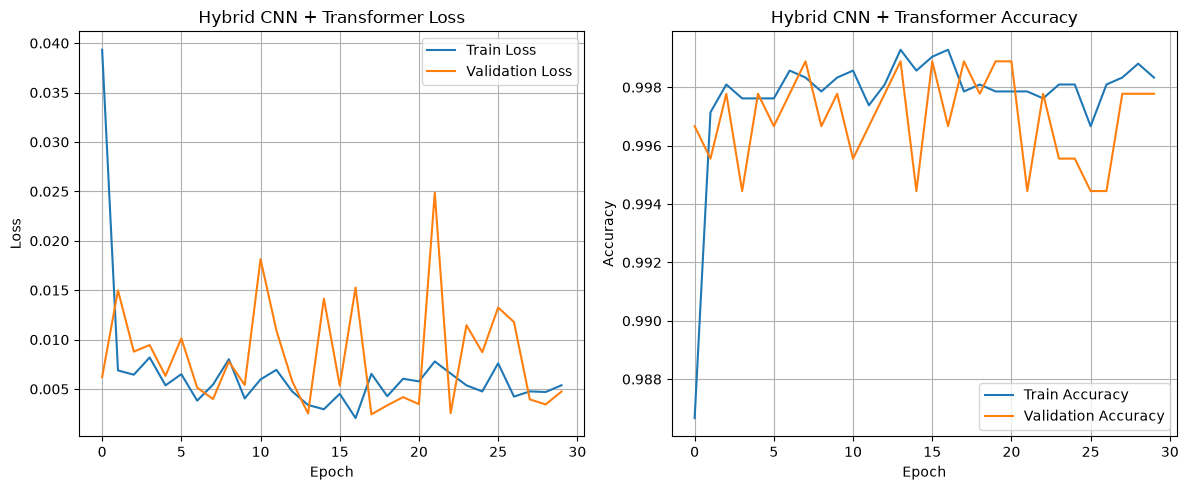

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_hybrid.history["loss"], label="Train Loss")
plt.plot(history_hybrid.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid CNN + Transformer Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_hybrid.history["accuracy"], label="Train Accuracy")
plt.plot(history_hybrid.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Hybrid CNN + Transformer Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### 03. Load the best saved model and evaluate

In [9]:
# Load the best saved hybrid model
hybrid_model = tf.keras.models.load_model(
    models_path / "ai_capstone_keras_hybrid.keras"
)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/layer.py:372: UserWarning: `build()` was called on layer 'transformer_block', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


In [10]:
# Val results
val_results = hybrid_model.evaluate(
    val_ds,
    verbose=0,
    return_dict=True
)

print(val_results)

{'accuracy': 0.9988889098167419, 'loss': 0.0024395522195845842}


In [11]:
# Test results
test_results = hybrid_model.evaluate(
    test_ds,
    verbose=0,
    return_dict=True
)

print(test_results)

{'accuracy': 0.995555579662323, 'loss': 0.02670583315193653}



Classification report:
                  precision    recall  f1-score   support

class_0_non_agri     0.9912    1.0000    0.9956       450
    class_1_agri     1.0000    0.9911    0.9955       450

        accuracy                         0.9956       900
       macro avg     0.9956    0.9956    0.9956       900
    weighted avg     0.9956    0.9956    0.9956       900


Confusion matrix:
[[450   0]
 [  4 446]]


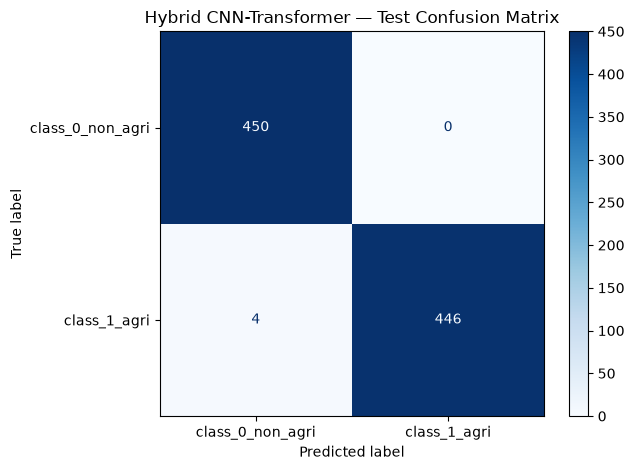

In [12]:
#  Collect test predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = hybrid_model.predict(images, verbose=0)

    labels = labels.numpy()
    if labels.ndim > 1:
        labels = np.argmax(labels, axis=1)

    y_true.extend(labels)
    y_pred.extend(np.argmax(probabilities, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

#  Print classification report
print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

#  Print and display confusion matrix
cm = confusion_matrix(y_true, y_pred)

print("\nConfusion matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Hybrid CNN-Transformer — Test Confusion Matrix")
plt.tight_layout()
plt.show()